## Tarea #: 1 (Machine learning 1. Especialización de Big Data y Analytics)

Tema: Exploración avanzada de datos, PCA, regresión y análisis crítico multivariado

Por: Maria Alejandra Colorado Ríos


## Punto 1.1.

Calcular la media, mediana, desviación estándar, moda y el número de repeticiones de la moda para las variables numéricas y categóricas del dataset. Realice un análisis crítico detallado sobre las implicaciones de estas medidas de tendencia central y dispersión respecto a la distribución e inequidad socioeconómica entre las ciudades.

Importar y preparar los datos

In [73]:
from pathlib import Path

import pandas as pd

ruta = Path("../../docs/analisisCiudades.xlsx")
datos = pd.read_excel(ruta, sheet_name="datos_originales")
print(f"Archivo: {ruta.as_posix()}")
print(f"Ciudades: {len(datos)}")
#datos

Archivo: ../../docs/analisisCiudades.xlsx
Ciudades: 30


Separar las variables numéricas y categóricas

In [74]:
# Variables numéricas
variables_numericas = [
    'GDP (USD Billion)',
    'Population (Millions)',
    'Unemployment Rate (%)',
    'Average Age',
    'Women (%)',
    'Men (%)',
    'Budget (USD Billion)'
]

# Variables categóricas
variables_categoricas = [
    'City',
    'Initial label',
    'Training'
]

Calcular las medidas para variables numéricas

In [75]:
# Crear una lista para almacenar resultados
resultados_numericos = []

for variable in variables_numericas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Identificar frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las modas
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima

    resultados_numericos.append({
        'Variable': variable,
        'n': len(serie),
        'Media': serie.mean(),
        'Mediana': serie.median(),
        'Desviación estándar': serie.std(ddof=0),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda
    })

# Crear DataFrame de resultados
tabla_numerica = pd.DataFrame(resultados_numericos)

# Mostrar resultados
display(tabla_numerica.round(4))

,Variable,n,Media,Mediana,Desviación estándar,Moda,Frecuencia de la moda
0,GDP (USD Billion),30,8.7500,2.65,19.5797,Sin moda,0
1,Population (Millions),30,0.7310,0.39,1.3301,"[0.08, 0.01]",2
2,Unemployment Rate (%),30,13.8333,13.45,2.8956,Sin moda,0
3,Average Age,30,29.2333,29.00,2.2013,[29],6
4,Women (%),30,51.5000,51.00,0.7638,[51],14
5,Men (%),30,48.5000,49.00,0.7638,[49],14
6,Budget (USD Billion),30,1.6500,0.60,3.3932,"[0.5, 0.1]",3


Calcular las medidas para variables categóricas

In [76]:
resultados_categoricos = []

for variable in variables_categoricas:

    serie = datos[variable].dropna()

    # Calcular frecuencias
    frecuencias = serie.value_counts()

    # Frecuencia máxima
    frecuencia_maxima = frecuencias.max()

    # Obtener todas las categorías modales
    modas = frecuencias[frecuencias == frecuencia_maxima].index.tolist()

    # Identificar si existe una moda real
    if frecuencia_maxima == 1:
        moda = "Sin moda"
        frecuencia_moda = 0
        porcentaje_moda = 0
    else:
        moda = modas
        frecuencia_moda = frecuencia_maxima
        porcentaje_moda = (frecuencia_maxima / len(serie)) * 100

    resultados_categoricos.append({
        'Variable': variable,
        'n': len(serie),
        'Moda': moda,
        'Frecuencia de la moda': frecuencia_moda,
        'Porcentaje de la moda': porcentaje_moda
    })

# Crear DataFrame de resultados
tabla_categorica = pd.DataFrame(resultados_categoricos)

# Mostrar resultados
display(tabla_categorica.round(2))

,Variable,n,Moda,Frecuencia de la moda,Porcentaje de la moda
0,City,30,Sin moda,0,0.00
1,Initial label,30,[2],10,33.33
2,Training,30,[Yes],21,70.00


# Análisis punto 1.1

1. Concentración económica y distribución del PIB (GDP)

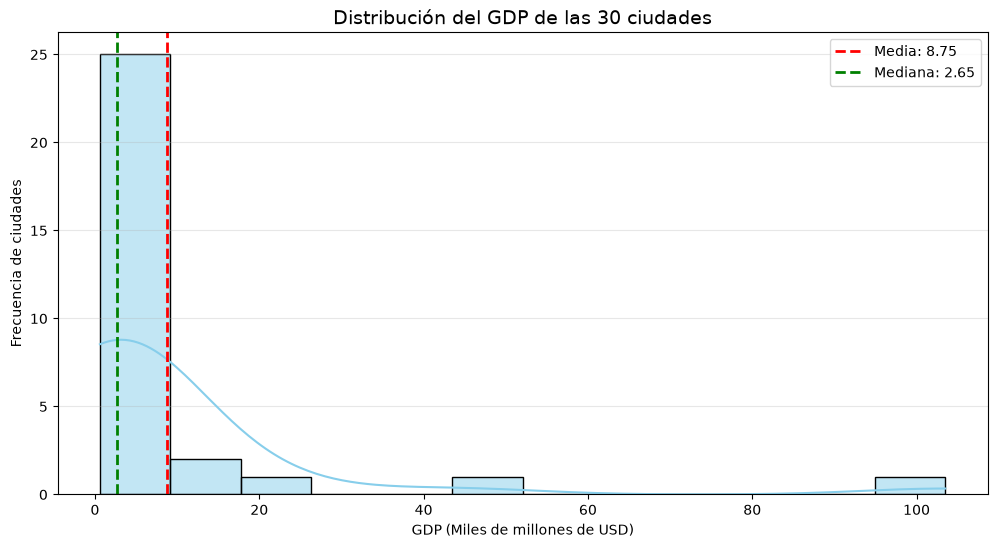

In [77]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar la variable GDP
gdp = datos["GDP (USD Billion)"].dropna()

# Calcular medidas estadísticas
media = gdp.mean()
mediana = gdp.median()

# Crear el histograma
plt.figure(figsize=(12, 6))

sns.histplot(
    gdp,
    bins=12,
    kde=True,
    color="skyblue",
    edgecolor="black"
)

# Agregar línea de la media
plt.axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media:.2f}"
)

# Agregar línea de la mediana
plt.axvline(
    mediana,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mediana: {mediana:.2f}"
)

# Configurar el gráfico
plt.title("Distribución del GDP de las 30 ciudades", fontsize=14)
plt.xlabel("GDP (Miles de millones de USD)")
plt.ylabel("Frecuencia de ciudades")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()


Se identifica que la media(8,75) es considerablemente superior a la mediana (2.65) para la variable GDP, lo que indica que la distribución está sesgada a la derecha, es decir, existen pocas ciudades con valor total de bienes y servicios producidos muy elevados que incrementan el promedio general. 

Por ejemplo, Bogotá registra un GDP de 103,5 mil millones de dólares, y Medellín de 44,1, mientras que la mayoría de las ciudades presentan valores inferiores a 10 mil millones.

Adicional, la desviación estándar de 19,57 mil millones supera ampliamente la media, lo que evidencia una dispersión muy alta de los datos.

Por lo tanto, esta concentración refleja una posible desigual económica entre ciudades, evidenciadas en sus capacidades productivas, niveles de generación de empleo, inversión y desarrollo empresarial.


2. Diferencias en el tamaño poblacional

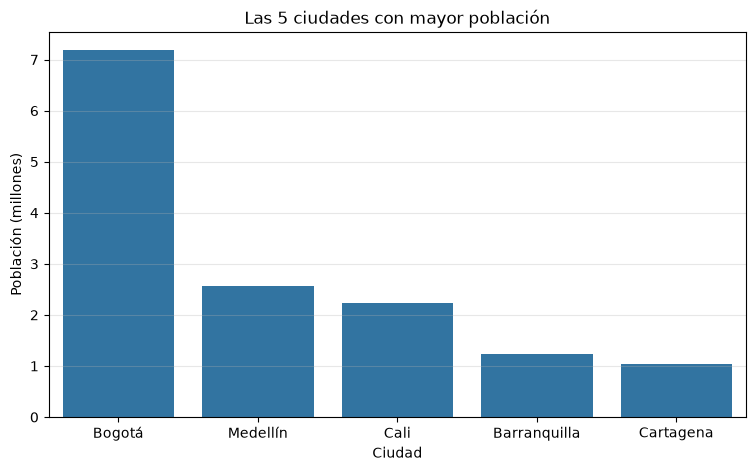

In [78]:

# Seleccionar las 10 ciudades más pobladas
top_5 = datos.nlargest(
    5,
    "Population (Millions)"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_5,
    x="City",
    y="Population (Millions)"
)

plt.title("Las 5 ciudades con mayor población")
plt.xlabel("Ciudad")
plt.ylabel("Población (millones)")
plt.grid(axis="y", alpha=0.3)

plt.show()


La población presenta un comportamiento similar al GDP, en donde se evidencia que la media es superior a la mediana y la desviación estándar es elevada.
Esto significa que, existen grandes diferencias en el tamaño poblacional de las ciudades. Por ejemplo, Bogotá, Medellín y Cali, concentran una cantidad importante de habitantes, mientras que otras presentan poblaciones menores.


### Análisis punto 1.1

Conclusión final:
El análisis estadístico de las 30 ciudades evidencia una marcada heterogeneidad socioeconómica, reflejada en la concentración de la actividad económica, la población y los recursos presupuestales en un grupo reducido de territorios. Esto se observa en las diferencias entre la media y la mediana, así como en las elevadas desviaciones estándar.
Asimismo, las tasas de desempleo presentan diferencias territoriales que pueden reflejar desigualdades en las oportunidades laborales. En contraste, variables demográficas como la edad promedio y la composición por sexo muestran un comportamiento más homogéneo.
En general, los resultados permiten identificar brechas territoriales en el desarrollo económico y la distribución de los recursos. No obstante, para evaluar con mayor profundidad las condiciones de vida y la distribución de la riqueza entre los habitantes, sería necesario complementar el análisis con indicadores como el PIB per cápita, la pobreza, el coeficiente de Gini y la informalidad laboral.


## Punto 1.2.

Generar un boxplot para analizar la distribución de las variables clave de la Tabla 1 utilizando las proporciones indicadas a continuación. Identifique y discuta formalmente la presencia de valores atípicos (outliers), su impacto analítico y su interpretación socioeconómica en el contexto urbano.


Generación de los boxplots

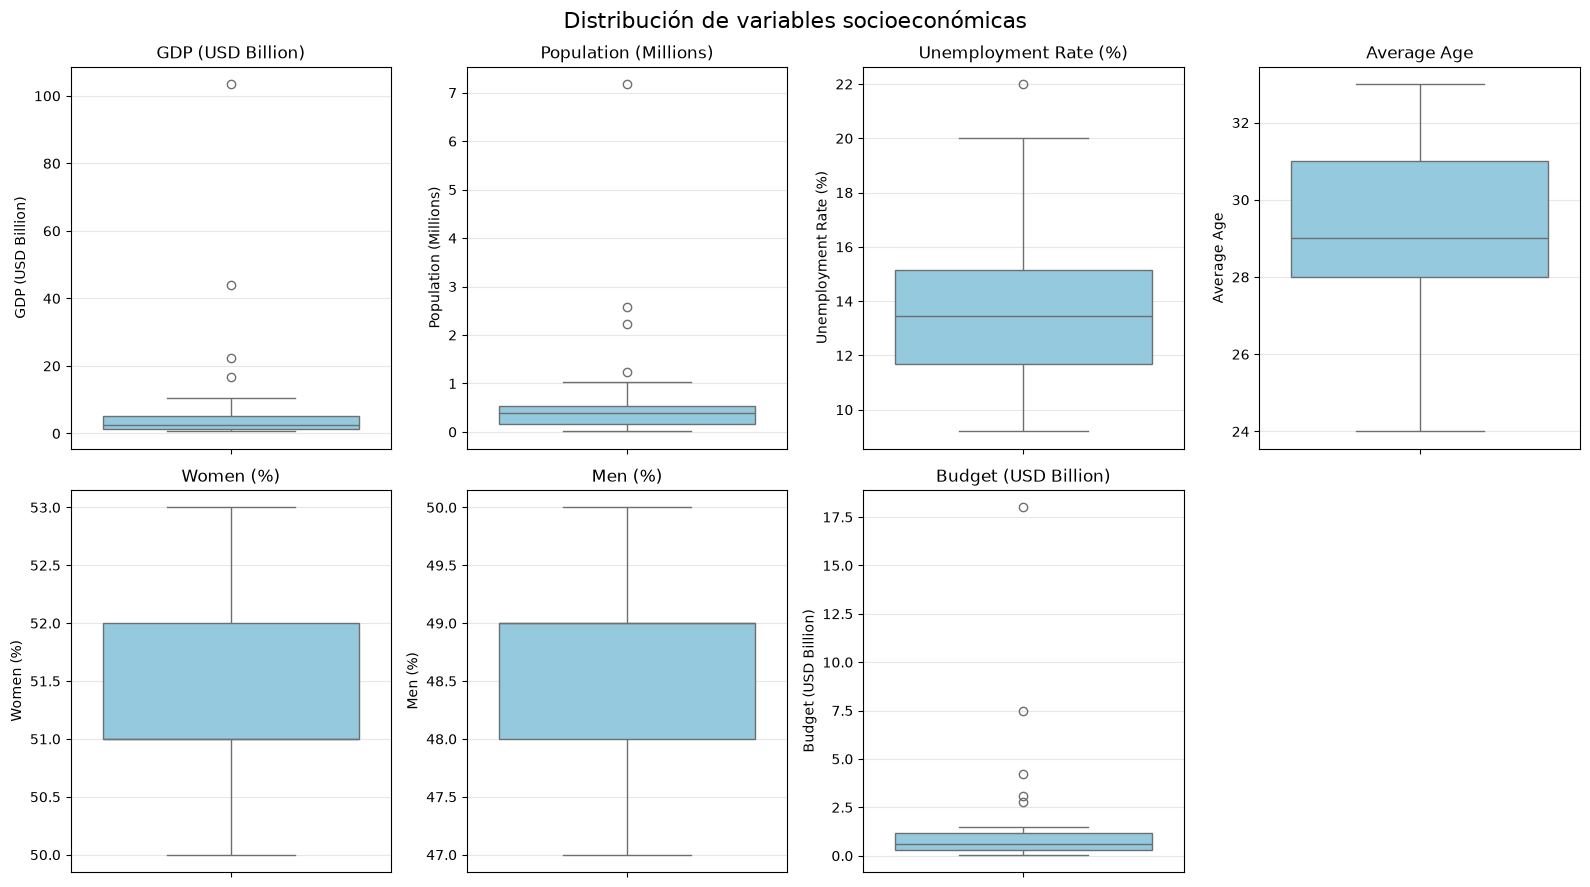

In [79]:

# Generar boxplots para todas las variables numéricas

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(variables_numericas):
    sns.boxplot(
        y=datos[variable],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(variable)
    axes[i].grid(axis="y", alpha=0.3)

# Ocultar el gráfico sobrante
axes[-1].axis("off")

plt.suptitle(
    "Distribución de variables socioeconómicas",
    fontsize=16
)

plt.tight_layout()
plt.show()


Identificar formalmente los valores atípicos

In [80]:

resultados_outliers = []

for variable in variables_numericas:

    q1 = datos[variable].quantile(0.25)
    q3 = datos[variable].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # Identificar ciudades con valores atípicos
    atipicos = datos[
        (datos[variable] < limite_inferior) |
        (datos[variable] > limite_superior)
    ]

    resultados_outliers.append({
        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Cantidad outliers": len(atipicos),
        "Ciudades": ", ".join(atipicos["City"])
    })

tabla_outliers = pd.DataFrame(resultados_outliers)

display(tabla_outliers.round(2))


,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Cantidad outliers,Ciudades
0,GDP (USD Billion),1.35,5.02,3.67,-4.16,10.54,4,"Bogotá, Medellín, Cali, Barranquilla"
1,Population (Millions),0.16,0.53,0.37,-0.39,1.08,4,"Bogotá, Medellín, Cali, Barranquilla"
2,Unemployment Rate (%),11.70,15.15,3.45,6.52,20.32,1,Puerto Carreño
3,Average Age,28.00,31.00,3.00,23.50,35.50,0,
4,Women (%),51.00,52.00,1.00,49.50,53.50,0,
5,Men (%),48.00,49.00,1.00,46.50,50.50,0,
6,Budget (USD Billion),0.30,1.18,0.88,-1.01,2.49,5,"Bogotá, Medellín, Cali, Barranquilla, Cartagena"


### Análisis punto 1.2

El análisis de los boxplots evidencia diferencias socioeconómicas importantes entre las 30 ciudades colombianas. Las variables PIB, población y presupuesto presentan una distribución asimétrica, con valores atípicos superiores que reflejan una concentración de la actividad económica, los habitantes y los recursos presupuestales en pocas ciudades.

Por otro lado, las variables demográficas, como edad promedio y distribución por sexo, presentan un comportamiento más homogéneo. En cuanto al desempleo, se identifica un valor atípico superior que evidencia diferencias en las condiciones laborales.

**En conclusión**, los resultados muestran desigualdades entre las ciudades, principalmente en las variables económicas. Estos valores atípicos deben considerarse en los análisis posteriores, ya que pueden afectar las medidas estadísticas y los resultados de los modelos de Machine Learning. Sin embargo, no deben eliminarse automáticamente, porque pueden representar características reales de las ciudades analizadas.

## Punto 1.3.

¿Cuál es la covarianza entre las variables X1 y X2?

Se toman como X1 y X2  las siguientes variables:

•	X1: GDP (USD Billion) — Producto Interno Bruto.

•	X2: Population (Millions) — Población.




In [81]:

# Seleccionar variables
x1 = datos["GDP (USD Billion)"]
x2 = datos["Population (Millions)"]

# Calcular las medias
media_x1 = x1.mean()
media_x2 = x2.mean()

# Calcular la covarianza poblacional manualmente
n = len(datos)

covarianza = (
    ((x1 - media_x1) * (x2 - media_x2)).sum() / n
)

print(f"Media GDP: {media_x1:.4f}")
print(f"Media población: {media_x2:.4f}")
print(f"Covarianza: {covarianza:.4f}")


Media GDP: 8.7500
Media población: 0.7310
Covarianza: 25.7957


### Diagrama de dispersión

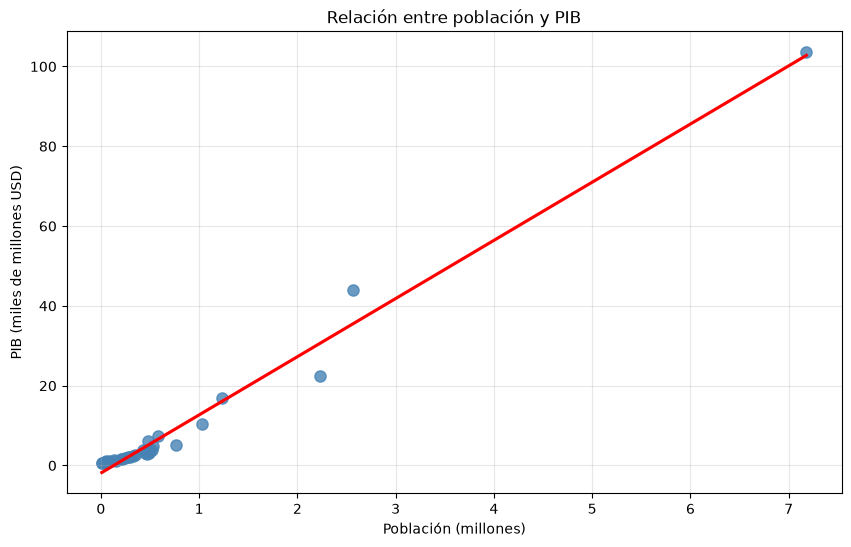

In [82]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=datos,
    x="Population (Millions)",
    y="GDP (USD Billion)",
    scatter_kws={"color": "steelblue", "s": 65},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Relación entre población y PIB")
plt.xlabel("Población (millones)")
plt.ylabel("PIB (miles de millones USD)")
plt.grid(alpha=0.3)
plt.show()


### Análisis punto 1.3

La covarianza entre el PIB (GDP) y la población es de **25,7957**, un valor positivo que indica que ambas variables tienden a aumentar conjuntamente.

Esto significa que las ciudades con mayor población, como Bogotá y Medellín, también tienden a presentar un mayor PIB, mientras que las ciudades menos pobladas generalmente tienen una menor actividad económica total.

**Conclusión:** Existe una relación positiva entre el tamaño poblacional y el PIB de las ciudades analizadas. Sin embargo, la covarianza no permite determinar por sí sola qué tan fuerte es esta relación, ya que depende de las unidades de medida. Para evaluar su intensidad utilizaremos la correlación en el punto 1.4.